In [2]:
%load_ext autoreload

In [3]:
%autoreload 2

In [ ]:
# This enables imports like
# from rect_prune_ood.lib.prunging import X
import matplotlib.pyplot as plt
import numpy as np

from rect_prune_ood.lib.plot.ablation_study_plot import plot_ablation_study
from rect_prune_ood.lib.util.paths import get_top_level_path
from rect_prune_ood.lib.util.plot import (
    plot_compare_methods,
    plot_triple_distribution_plot,
)

## Plot confidences

In [37]:
id_data = np.load(get_top_level_path() + "/results/imagenet/baseline/id_imagenet.npy", allow_pickle=True).item()
ood_dtd = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_dtd.npy", allow_pickle=True).item()
ood_places = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_places.npy", allow_pickle=True).item()
ood_inat = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_inat.npy", allow_pickle=True).item()
ood_sun = np.load(get_top_level_path() + "/results/imagenet/baseline/ood_sun.npy", allow_pickle=True).item()

In [71]:
# Find values where the prediction is correct 
def filter_correct(data):
    correct = []
    for i in range(len(data)):
        if data["prediction"][i] == data["label"][i]:
            correct.append(data["confidence"] * 100) 
    return np.concatenate(correct)

# Find values where the prediction is incorrect
id_data_correct = filter_correct(id_data)

In [72]:
id_data_bins = np.histogram(id_data_correct, bins=1000, range=(0, 100), density=False)
# ood_dtd_bins = np.histogram(ood_combined, bins=1000, range=(0, 100), density=False)

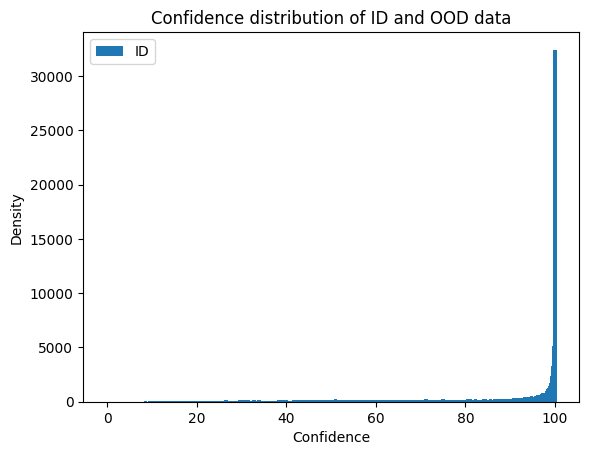

In [73]:
# Plotting the 2 distributions
# plt.bar(np.linspace(0, 100, 1000), ood_dtd_bins[0], label="OOD")
plt.bar(np.linspace(0, 100, 1000),id_data_bins[0], label="ID")
plt.legend()
plt.xlabel("Confidence")
plt.ylabel("Density")
plt.title("Confidence distribution of ID and OOD data")
plt.show()


## Plot Energy Score Distribution

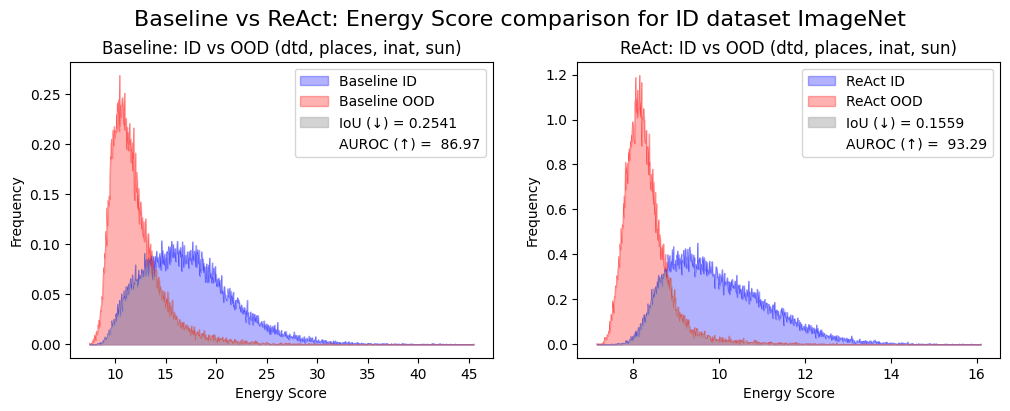

In [ ]:
plot_compare_methods(
    ood_datasets=["dtd", "places", "inat", "sun"],
    id_dataset="imagenet",
    first_method="baseline",
    second_method="react",
    score_function="energy_score",
    plot_iou=True,
    plot_auroc=True,
    use_full_spec=False,
    scale_y=False
)

id_data = np.load(get_top_level_path() + "/results/imagenet/baseline/imagenet.npy", allow_pickle=True).item()
perturbed_data = np.load(get_top_level_path() + "/results/imagenet/baseline/imagenet_perturbed.npy", allow_pickle=True).item()
ood_data = np.load(get_top_level_path() + "/results/imagenet/baseline/dtd.npy", allow_pickle=True).item()

scores = {}
scores["id"] = id_data["energy_score"]
scores["id_perturbed"] = perturbed_data["energy_score"]
scores["ood"] = ood_data["energy_score"]
plot_triple_distribution_plot(scores["id"], scores["id_perturbed"], scores["ood"])

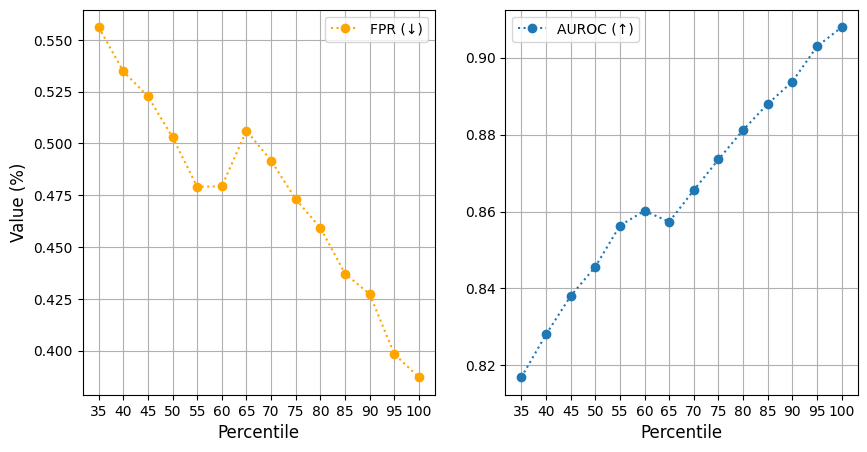

In [6]:
plot_ablation_study(method_name="ashs_apesp")